# Classification from Scratch V1.3 (NumPy only) — Response, deeper MLP, k-fold validation (k=5)

**Version:** V1.3 (k-fold validation — deeper MLP). **Role:** mandatory from-scratch twin of
`classification_pytorch_V1_3.ipynb` — no torch. `sklearn` ONLY for split/scaler/metrics. Identical
`ScratchDeepMLP` architecture and hypers as `classification_scratch_V1_1.ipynb`, copied verbatim and
wrapped in the same 5-fold `StratifiedKFold` loop the oracle used (median-fill + scaler refit per fold,
fresh init per fold, no checkpointing — same convention as the V1.1 single split). Combined with the
oracle's per-fold F1 into one grouped bar chart. Weights →
`./weights_V1_3/classification_scratch_kfold_metrics.json`.

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

assert os.path.exists("weights_V1_3/classification_pytorch_kfold_metrics.json"), "run classification_pytorch_V1_3.ipynb first"
SEED = 42
np.random.seed(SEED)
os.makedirs("weights_V1_3", exist_ok=True)

## 1. LOAD DATA (identical to V1.1)

In [2]:
df = pd.read_csv("marketing_campaign.csv", sep="\t")
df = df.drop(columns=["ID", "Z_CostContact", "Z_Revenue"])
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
ref_date = df["Dt_Customer"].max()
df["Customer_Tenure_Days"] = (ref_date - df["Dt_Customer"]).dt.days
df["Age"] = 2014 - df["Year_Birth"]
df = df[~df["Year_Birth"].isin([1893, 1899, 1900])].copy()
df = df[df["Income"] != 666666].copy()  # drop $666,666 income outlier (same treatment as Year_Birth sentinels)
df["Marital_Status"] = df["Marital_Status"].replace({"Absurd": "Single", "YOLO": "Single", "Alone": "Single"})
print("cleaned:", df.shape, "| Response rate:", round(df["Response"].mean(), 4))

CLF_NUMERIC = [
    "AcceptedCmp5", "AcceptedCmp3", "MntWines", "MntMeatProducts",
    "NumCatalogPurchases", "Recency", "Customer_Tenure_Days", "MntGoldProds",
    "Income", "MntFruits",
    "AcceptedCmp1", "AcceptedCmp2", "NumWebPurchases", "MntSweetProducts",
    "MntFishProducts", "NumStorePurchases", "Age",
]
X_num = df[CLF_NUMERIC].copy()
X_cat = pd.get_dummies(df[["Marital_Status"]], dtype=float)
X_full = pd.concat([X_num, X_cat], axis=1)
FEATURE_COLS = list(X_full.columns)
y_full = df["Response"].astype(float).values
inc_idx = FEATURE_COLS.index("Income")
print(f"features: {len(CLF_NUMERIC)} numeric + {X_cat.shape[1]} dummies = {len(FEATURE_COLS)} dims")

class NumpyDataset:
    def __init__(self, X, y):
        self.X = np.asarray(X, dtype=np.float64)
        self.y = np.asarray(y, dtype=np.float64).reshape(-1, 1)
    def __len__(self):
        return self.X.shape[0]
    def __getitem__(self, i):
        return self.X[i], self.y[i]

def batch_generator(ds, batch_size=64, shuffle=True, rng=None):
    idx = np.arange(len(ds))
    if shuffle:
        idx = rng.permutation(idx)
    for s in range(0, len(ds), batch_size):
        b = idx[s:s + batch_size]
        yield ds.X[b], ds.y[b]

cleaned: (2236, 28) | Response rate: 0.1494
features: 17 numeric + 5 dummies = 22 dims


## 2. MODEL: ScratchDeepMLP (identical to V1.1, clean backward: BN + residual split)

In [3]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

class ScratchDeepMLP:
    def __init__(self, in_dim=22, h=64, p=0.2, seed=42):
        rng = np.random.default_rng(seed)
        self.W1 = rng.standard_normal((in_dim, h)) * np.sqrt(2.0 / in_dim)
        self.b1 = np.zeros(h)
        self.g1 = np.ones(h); self.s1 = np.zeros(h)
        self.rm1 = np.zeros(h); self.rv1 = np.ones(h)
        self.W2 = rng.standard_normal((h, h)) * np.sqrt(2.0 / h)
        self.b2 = np.zeros(h)
        self.g2 = np.ones(h); self.s2 = np.zeros(h)
        self.rm2 = np.zeros(h); self.rv2 = np.ones(h)
        self.W3 = rng.standard_normal((h, 1)) * np.sqrt(2.0 / h)
        self.b3 = np.zeros(1)
        self.p = p
        self.drng = np.random.default_rng(seed + 1)
        self.adam = {n: [np.zeros_like(getattr(self, n)), np.zeros_like(getattr(self, n))]
                     for n in ("W1", "b1", "g1", "s1", "W2", "b2", "g2", "s2", "W3", "b3")}
        self.t = 0
    def _bn(self, x, g, s, rm, rv, train, mom=0.1, eps=1e-5):
        if train:
            B = len(x); mu = x.mean(axis=0); va = x.var(axis=0)
            rm[:] = (1 - mom) * rm + mom * mu
            rv[:] = (1 - mom) * rv + mom * (va * B / max(B - 1, 1))
            xh = (x - mu) / np.sqrt(va + eps)
            cache = (x, xh, mu, va)
        else:
            xh = (x - rm) / np.sqrt(rv + eps); cache = None
        return g * xh + s, cache
    @staticmethod
    def _bn_backward(dout, cache, g, eps=1e-5):
        x, xh, mu, va = cache; N = len(x)
        dg = (dout * xh).sum(axis=0); db = dout.sum(axis=0)
        dxh = dout * g
        ivar = 1.0 / np.sqrt(va + eps)
        dvar = (dxh * (x - mu) * -0.5 * (va + eps) ** -1.5).sum(axis=0)
        dmu = (dxh * -ivar).sum(axis=0) + dvar * (-2.0 * (x - mu)).mean(axis=0)
        dx = dxh * ivar + dvar * 2.0 * (x - mu) / N + dmu / N
        return dx, dg, db
    def forward(self, X, train):
        Z1 = X @ self.W1 + self.b1
        B1, c1 = self._bn(Z1, self.g1, self.s1, self.rm1, self.rv1, train)
        A1 = np.maximum(0, B1)
        m1 = (self.drng.random(A1.shape) >= self.p) / (1 - self.p) if train else None
        D1 = A1 * m1 if train else A1
        Z2 = D1 @ self.W2 + self.b2
        B2, c2 = self._bn(Z2, self.g2, self.s2, self.rm2, self.rv2, train)
        S = B2 + D1
        A2 = np.maximum(0, S)
        m2 = (self.drng.random(A2.shape) >= self.p) / (1 - self.p) if train else None
        D2 = A2 * m2 if train else A2
        out = D2 @ self.W3 + self.b3
        return {"Z1": Z1, "c1": c1, "A1": A1, "m1": m1, "D1": D1, "Z2": Z2,
                "c2": c2, "S": S, "A2": A2, "m2": m2, "D2": D2, "out": out}
    def predict_proba(self, X):
        return sigmoid(self.forward(X, train=False)["out"]).ravel()
    def backward(self, dout, c, Xb):
        dW3 = c["D2"].T @ dout; db3 = dout.sum(axis=0)
        dD2 = dout @ self.W3.T
        dA2 = dD2 * (c["m2"] if c["m2"] is not None else 1.0)
        dS = dA2 * (c["S"] > 0)
        dB2, dg2, ds2 = self._bn_backward(dS, c["c2"], self.g2)
        dW2 = c["D1"].T @ dB2; db2 = dB2.sum(axis=0)
        dD1 = dB2 @ self.W2.T + dS  # matmul branch + residual skip branch
        dA1 = dD1 * (c["m1"] if c["m1"] is not None else 1.0)
        dZ1, dg1, ds1 = self._bn_backward(dA1 * (c["A1"] > 0), c["c1"], self.g1)
        dW1 = Xb.T @ dZ1; db1 = dZ1.sum(axis=0)
        return {"W3": dW3, "b3": db3, "W2": dW2, "b2": db2, "g2": dg2, "s2": ds2,
                "W1": dW1, "b1": db1, "g1": dg1, "s1": ds1}
    def adam_step(self, grads, lr, wd=1e-4, b1=0.9, b2=0.999, eps=1e-8):
        self.t += 1
        for name, g in grads.items():
            g = g + wd * getattr(self, name)
            m, v = self.adam[name]
            m[:] = b1 * m + (1 - b1) * g
            v[:] = b2 * v + (1 - b2) * g * g
            mhat = m / (1 - b1 ** self.t); vhat = v / (1 - b2 ** self.t)
            getattr(self, name).__isub__(lr * mhat / (np.sqrt(vhat) + eps))

## K-fold training (k=5) — fresh ScratchDeepMLP per fold, no checkpointing

Same convention as the oracle above: fixed 100 epochs per fold, no best-epoch checkpoint selection.
Saved to `weights_V1_3/classification_scratch_kfold_metrics.json`.

In [4]:
K = 5
LR0, BATCH = 1e-3, 64
EPS = 1e-12

def bce_plain(proba, y):
    p = np.clip(proba, EPS, 1 - EPS)
    return float(-(y * np.log(p) + (1 - y) * np.log(1 - p)).mean())

skf = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEED)
X_all = X_full.values
fold_rows = []
for fold, (tr_idx, va_idx) in enumerate(skf.split(X_all, y_full), start=1):
    Xtr_f, Xva_f = X_all[tr_idx].copy(), X_all[va_idx].copy()
    ytr_f, yva_f = y_full[tr_idx], y_full[va_idx]
    med_f = np.nanmedian(Xtr_f[:, inc_idx])
    for arr in (Xtr_f, Xva_f):
        arr[:, inc_idx] = np.where(np.isnan(arr[:, inc_idx]), med_f, arr[:, inc_idx])
    sc_f = StandardScaler().fit(Xtr_f)
    Xtr_fs, Xva_fs = sc_f.transform(Xtr_f), sc_f.transform(Xva_f)
    m = ScratchDeepMLP(in_dim=len(FEATURE_COLS), h=64, p=0.2, seed=SEED + fold)
    pos_f, neg_f = (ytr_f == 1).sum(), (ytr_f == 0).sum()
    pw_f = neg_f / pos_f
    rng_f = np.random.default_rng(SEED + fold)
    train_ds_f = NumpyDataset(Xtr_fs, ytr_f)
    for epoch in range(100):
        lr = 0.5 * LR0 * (1 + np.cos(np.pi * epoch / 100))
        for xb, yb in batch_generator(train_ds_f, BATCH, True, rng_f):
            B = len(xb)
            c = m.forward(xb, train=True)
            prob = sigmoid(c["out"])
            dlogit = (prob + prob * yb * (pw_f - 1) - pw_f * yb) / B
            m.adam_step(m.backward(dlogit, c, xb), lr)
    prob_v = m.predict_proba(Xva_fs)
    pred_v = (prob_v >= 0.5).astype(int)
    loss_v = bce_plain(prob_v.reshape(-1, 1), yva_f.reshape(-1, 1))
    fold_rows.append({
        "fold": fold,
        "test_loss_BCE": round(float(loss_v), 4),
        "accuracy": round(float(accuracy_score(yva_f, pred_v)), 4),
        "precision": round(float(precision_score(yva_f, pred_v, zero_division=0)), 4),
        "recall": round(float(recall_score(yva_f, pred_v, zero_division=0)), 4),
        "f1": round(float(f1_score(yva_f, pred_v, zero_division=0)), 4),
        "roc_auc": round(float(roc_auc_score(yva_f, prob_v)), 4),
    })
    print(f"fold {fold}: F1={fold_rows[-1]['f1']:.4f} BCE={fold_rows[-1]['test_loss_BCE']:.4f}")

kfold_df = pd.DataFrame(fold_rows)
summary = {k: {"mean": round(float(kfold_df[k].mean()), 4), "std": round(float(kfold_df[k].std()), 4)}
           for k in ("test_loss_BCE", "accuracy", "precision", "recall", "f1", "roc_auc")}
print(kfold_df.to_string(index=False))
print(json.dumps(summary, indent=2))
with open("weights_V1_3/classification_scratch_kfold_metrics.json", "w") as f:
    json.dump({"k": K, "folds": fold_rows, "summary": summary}, f, indent=2)

fold 1: F1=0.5952 BCE=0.3400


fold 2: F1=0.5698 BCE=0.4104


fold 3: F1=0.5098 BCE=0.4546


fold 4: F1=0.5361 BCE=0.4278


fold 5: F1=0.5714 BCE=0.3932
 fold  test_loss_BCE  accuracy  precision  recall     f1  roc_auc
    1         0.3400    0.8482     0.4950  0.7463 0.5952   0.9036
    2         0.4104    0.8277     0.4554  0.7612 0.5698   0.8726
    3         0.4546    0.7763     0.3796  0.7761 0.5098   0.8666
    4         0.4278    0.7987     0.4094  0.7761 0.5361   0.8780
    5         0.3932    0.8054     0.4234  0.8788 0.5714   0.9010
{
  "test_loss_BCE": {
    "mean": 0.4052,
    "std": 0.0429
  },
  "accuracy": {
    "mean": 0.8113,
    "std": 0.0276
  },
  "precision": {
    "mean": 0.4326,
    "std": 0.0443
  },
  "recall": {
    "mean": 0.7877,
    "std": 0.0524
  },
  "f1": {
    "mean": 0.5565,
    "std": 0.0335
  },
  "roc_auc": {
    "mean": 0.8844,
    "std": 0.0169
  }
}


## Combined summary plot (oracle vs scratch, per-fold F1)

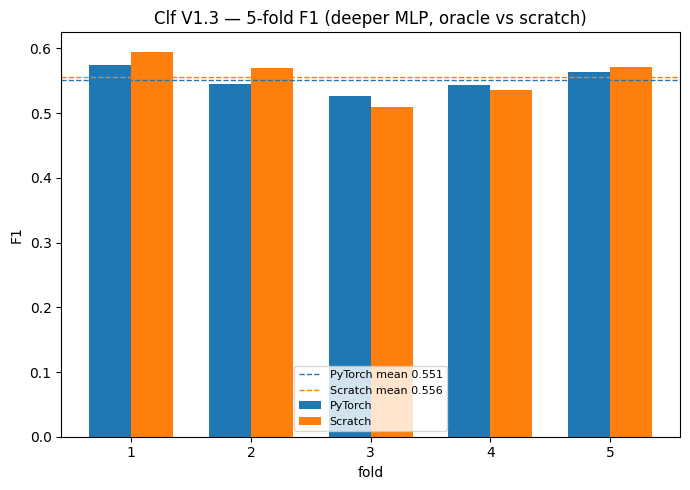

PyTorch F1 mean+-std: 0.5508 0.0191
Scratch F1 mean+-std: 0.5565 0.0335


In [5]:
import matplotlib.pyplot as plt

pyt_kf = json.load(open("weights_V1_3/classification_pytorch_kfold_metrics.json"))
scr_kf = json.load(open("weights_V1_3/classification_scratch_kfold_metrics.json"))
pyt_f1 = [r["f1"] for r in pyt_kf["folds"]]
scr_f1 = [r["f1"] for r in scr_kf["folds"]]
folds_x = np.arange(1, K + 1)
width = 0.35
plt.figure(figsize=(7, 5))
plt.bar(folds_x - width / 2, pyt_f1, width, label="PyTorch")
plt.bar(folds_x + width / 2, scr_f1, width, label="Scratch")
plt.axhline(pyt_kf["summary"]["f1"]["mean"], color="C0", linestyle="--", linewidth=1,
            label=f"PyTorch mean {pyt_kf['summary']['f1']['mean']:.3f}")
plt.axhline(scr_kf["summary"]["f1"]["mean"], color="C1", linestyle="--", linewidth=1,
            label=f"Scratch mean {scr_kf['summary']['f1']['mean']:.3f}")
plt.xticks(folds_x); plt.xlabel("fold"); plt.ylabel("F1")
plt.title("Clf V1.3 — 5-fold F1 (deeper MLP, oracle vs scratch)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("media/kfold_clf_V1_3.png", dpi=150)
plt.show()

print("PyTorch F1 mean+-std:", pyt_kf["summary"]["f1"]["mean"], pyt_kf["summary"]["f1"]["std"])
print("Scratch F1 mean+-std:", scr_kf["summary"]["f1"]["mean"], scr_kf["summary"]["f1"]["std"])